<a href="https://colab.research.google.com/github/Nasim-Amani/solar/blob/main/Dataset_Guide.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Dataset Guide: `solar_data_final_columns.csv`


Outdoor solar and PV measurements, recorded every second from 15 to 27 February 2013. The file has 1,015,991 rows and 11 complete days (Feb 16 to Feb 26).

## 1. How we got to this file

We started from 17 raw Excel files and worked through three notebooks. Each one saves a CSV that the next one reads.

| Step | Notebook | What we did | Output |
|---|---|---|---|
| 0 | `0cleaned_solar_data_Oct26` | Merged the 17 Excel files, built one `DateTime` column, removed 17 exact duplicate rows, and fixed repeated timestamps so that rows are 1 s apart. Dropped columns that were empty (`Parameter 8`, `PV 2 GT V`, `PV 3 Tr V`). | `cleaned_solar_data_Oct26.csv` |
| 1 | `1solar_data_SolarRad_clean` | The radiation sensor showed about 2.7 W/m² at night instead of 0. We treated this as a sensor offset, subtracted it from all values and set negatives to 0. We also added flags for daylight and for complete days. | `solar_data_SolarRad_clean.csv` |
| 2 | `2solar_data_final_columns` | Checked every sensor. Two current columns did not work (`PV_1_SA_I`, `PV_3_Tr_I`) and were removed. We found that `PV_1_SA_V` is an open-circuit voltage and that PV_4 is a small panel charging a battery. | `solar_data_final_columns.csv` |

The detailed steps and checks are in those notebooks.

## 2. Columns

| Column | What it is |
|---|---|
| `Solar_Rad_clean` | Solar irradiance after removing the night offset (W/m²). **Use this one.** |
| `Solar_Rad` | Raw irradiance, kept only for reference (W/m²) |
| `Amb_Tempr` | Air temperature (°C) |
| `Tempr_PV_1`, `Tempr_PV_2`, `Tempr_PV_3` | Temperatures of three PV modules (°C) |
| `PV_1_SA_V` | Voltage of module 1. The module is not connected to a load, so this is its open-circuit voltage, Voc (V) |
| `PV_2_GT_I` | Current of module 2 (A). It follows irradiance very closely |
| `PV_4_Hor_V`, `PV_4_Hor_I`, `PV_4_Hor_P` | Voltage (V), current (A) and power (W) of a small panel that charges a battery |
| `PV4_state` | What PV_4 is doing: `night`, `charging` or `disconnected` |
| `daylight` | True when there is measurable sunlight (1-min median of `Solar_Rad_clean` above 1 W/m²) |
| `full_day` | True for the 11 complete days. Feb 15 starts at 18:49 and Feb 27 ends at 13:03 |

## 3. Loading the data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

plt.rcParams.update({"figure.dpi": 110, "axes.grid": True, "grid.alpha": 0.3})

df = pd.read_csv("solar_data_final_columns.csv", index_col="DateTime", parse_dates=["DateTime"])

print(f"Rows: {len(df):,}")
print(f"From {df.index[0]} to {df.index[-1]}")
print(f"Complete days: {df.loc[df['full_day']].index.normalize().nunique()}")
print(f"Daylight rows: {df['daylight'].mean():.1%}")

Rows: 1,015,991
From 2013-02-15 18:49:44 to 2013-02-27 13:03:03
Complete days: 11
Daylight rows: 48.4%


## 4. Important

- Use `Solar_Rad_clean`, not `Solar_Rad`. The raw column never reaches 0 at night, so it is always about 2.7 W/m² too high.
- Small night values in the other sensors were not corrected. At night `PV_2_GT_I` shows about 0.04 A and `PV_4_Hor_V` about −0.6 V. These are small compared with daytime values. `PV_1_SA_V` is also above 0 at night on average, but this mostly comes from twilight, when the voltage already rises in very weak light.
- PV_4 is controlled by a battery charger. It charges in the morning until about 09:00 and is then disconnected for most of the day. Its current and power show the state of the battery, not the weather.
- We assume the sharp drops in irradiance are clouds. The drops appear at the same moment in two separate sensors (irradiance and `PV_2_GT_I`), so a sensor fault is unlikely.
- Short peaks above the clear-day level (up to 1,022 W/m²) are probably "cloud enhancement", when light reflected from the edge of a cloud briefly adds to direct sunlight. We kept these values.

## 5. a clear day and a cloudy day

The plot shows the main variables (10-s means) on Feb 21 (clear) and Feb 25 (cloudy).

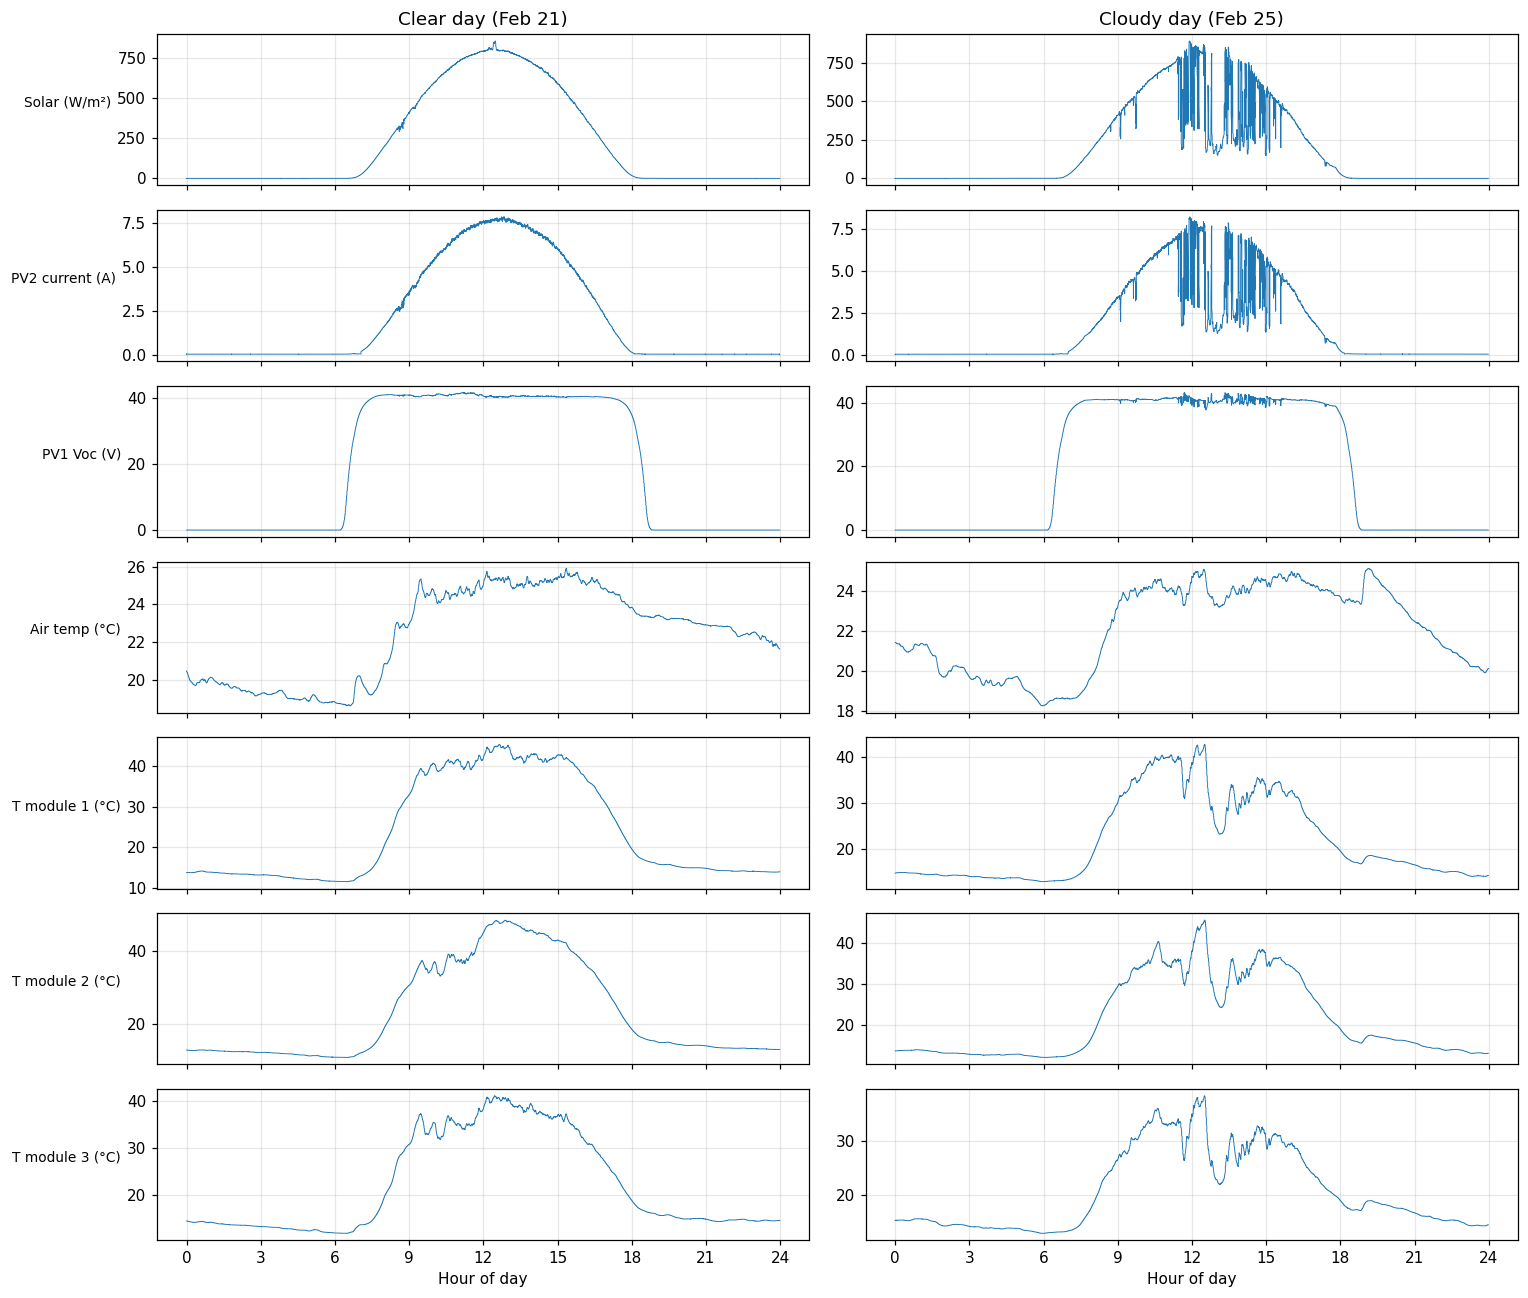

In [2]:
CORE = {"Solar_Rad_clean": "Solar (W/m²)", "PV_2_GT_I": "PV2 current (A)", "PV_1_SA_V": "PV1 Voc (V)",
        "Amb_Tempr": "Air temp (°C)", "Tempr_PV_1": "T module 1 (°C)",
        "Tempr_PV_2": "T module 2 (°C)", "Tempr_PV_3": "T module 3 (°C)"}
days = {"Clear day (Feb 21)": "2013-02-21", "Cloudy day (Feb 25)": "2013-02-25"}

fig, axes = plt.subplots(len(CORE), 2, figsize=(14, 1.7 * len(CORE)), sharex="col")
for j, (title, d) in enumerate(days.items()):
    x = df.loc[d, list(CORE)].resample("10s").mean()
    hours = x.index.hour + x.index.minute / 60
    for i, (col, label) in enumerate(CORE.items()):
        axes[i, j].plot(hours, x[col], lw=0.6)
        if j == 0:
            axes[i, j].set_ylabel(label, rotation=0, ha="right", fontsize=9)
    axes[0, j].set_title(title)
    axes[-1, j].set_xticks(range(0, 25, 3))
    axes[-1, j].set_xlabel("Hour of day")
plt.tight_layout()
plt.show()

On the clear day, irradiance and PV2 current form a smooth curve. On the cloudy day both show the same sharp drops at the same times. The module temperatures follow the sun as well, but they change more slowly and the drops are smoothed out. Air temperature changes little during the day, and Voc jumps up at sunrise and then stays around 40 V.

## 6. What we found interesting

### 6.1 PV2 current behaves like a second irradiance sensor

In [3]:
if "m1" not in globals():
    SHORT = {"Solar_Rad_clean": "Solar", "PV_2_GT_I": "PV2_I", "PV_1_SA_V": "PV1_Voc", "Amb_Tempr": "T_amb",
             "Tempr_PV_1": "T_PV1", "Tempr_PV_2": "T_PV2", "Tempr_PV_3": "T_PV3"}
    m1 = (df.loc[df["daylight"] & df["full_day"], list(SHORT)]
            .resample("1min").mean().dropna().rename(columns=SHORT))

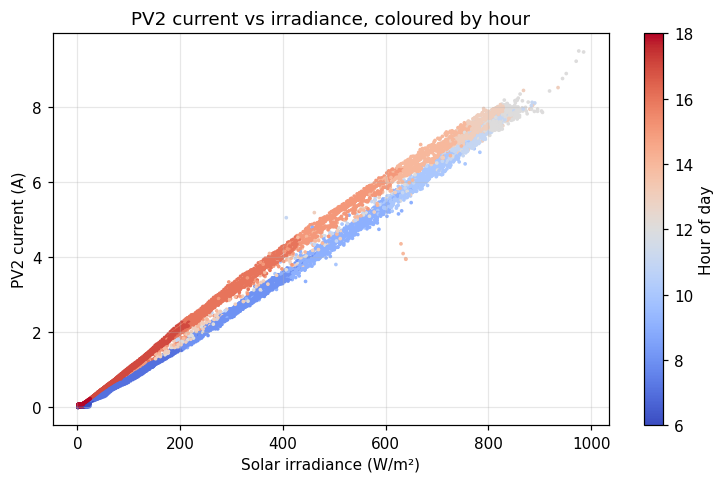

In [4]:
fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(m1["Solar"], m1["PV2_I"], c=m1.index.hour, s=2, cmap="coolwarm")
fig.colorbar(sc, ax=ax, label="Hour of day")
ax.set_xlabel("Solar irradiance (W/m²)")
ax.set_ylabel("PV2 current (A)")
ax.set_title("PV2 current vs irradiance, coloured by hour")
plt.tight_layout()
plt.show()

The points lie close to a straight line, as expected: the current of a solar module grows in proportion to the light it receives.

The colours show two bands, morning and afternoon. At the same irradiance, the module gives about 15% more current in the afternoon (e.g. ~4.3 A vs ~3.7 A at 400 W/m²). The module probably receives relatively more light in the afternoon than the flat radiation sensor, for example because it is tilted slightly towards the west. (The setup details are not documented)

So `PV_2_GT_I` follows irradiance closely and could even serve as a backup irradiance sensor.

### 6.2 Voc follows the physics of solar cells

Effect of module temperature on Voc: -0.131 V/°C = -0.325 %/°C


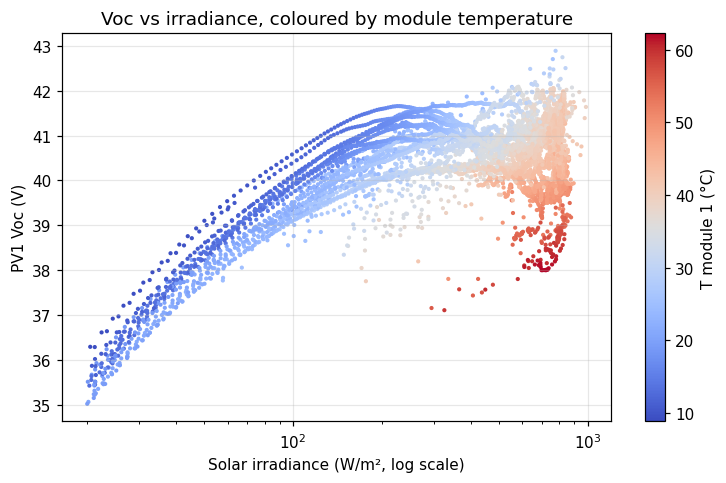

In [5]:
v = m1[m1["Solar"] > 20]
X = np.column_stack([np.ones(len(v)), np.log(v["Solar"]), v["T_PV1"]])
coef, *_ = np.linalg.lstsq(X, v["PV1_Voc"], rcond=None)
print(f"Effect of module temperature on Voc: {coef[2]:.3f} V/°C = {100 * coef[2] / v['PV1_Voc'].mean():.3f} %/°C")

fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(v["Solar"], v["PV1_Voc"], c=v["T_PV1"], s=3, cmap="coolwarm")
ax.set_xscale("log")
ax.set_xlabel("Solar irradiance (W/m², log scale)")
ax.set_ylabel("PV1 Voc (V)")
ax.set_title("Voc vs irradiance, coloured by module temperature")
fig.colorbar(sc, ax=ax, label="T module 1 (°C)")
plt.tight_layout()
plt.show()

On the log scale, Voc rises almost in a straight line in weak light, from about 35 V at 20 W/m² to about 41 V at 200 W/m². This is the logarithmic behaviour expected for solar cells. Above roughly 400 W/m², Voc stops rising and even falls to about 38 V. These are the hottest minutes (red), when the module heats up so much that the temperature effect is stronger than the effect of extra light. At the same irradiance, cool minutes (blue) generally have a higher voltage than hot ones.

Because irradiance and module temperature rise together during the day, we used a regression with both as inputs, Voc = a + b·ln(irradiance) + c·temperature. This separates the two effects. The temperature coefficient c shows how Voc changes with temperature at the same irradiance: it drops by 0.325 % for every 1 °C. This is the typical value for silicon modules (about 0.3 to 0.35 %/°C). Together with the logarithmic rise, this strongly supports that `PV_1_SA_V` is an open-circuit voltage.

### 6.3 Module temperature depends on more than the current sunlight

We plotted module temperature against irradiance for one clear day and coloured the points by time of day.

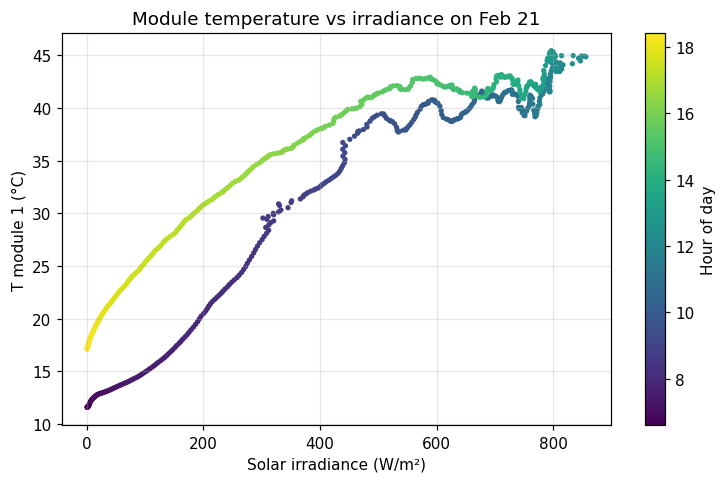

In [6]:
one = df.loc["2013-02-21"]
one = one[one["daylight"]].resample("1min").mean(numeric_only=True)
hour = one.index.hour + one.index.minute / 60

fig, ax = plt.subplots(figsize=(7, 4.5))
sc = ax.scatter(one["Solar_Rad_clean"], one["Tempr_PV_1"], c=hour, s=6, cmap="viridis")
ax.set_xlabel("Solar irradiance (W/m²)")
ax.set_ylabel("T module 1 (°C)")
ax.set_title("Module temperature vs irradiance on Feb 21")
fig.colorbar(sc, ax=ax, label="Hour of day")
plt.tight_layout()
plt.show()

The points form a loop instead of a single line. At the same irradiance, the module is much warmer in the afternoon than in the morning (about 31 °C vs 20 °C at 200 W/m²). So module temperature does not depend only on the irradiance at that moment.